# ***Phase 2 ML Project***




In [1]:
# memory check
import psutil
ram = psutil.virtual_memory().total / (1024**3)
print(f"Total RAM: {ram:.1f} GB")

ram_available = psutil.virtual_memory().available / (1024**3)
print(f"Available RAM: {ram_available:.1f} GB")

Total RAM: 12.7 GB
Available RAM: 11.7 GB


In [6]:
import psutil
available = psutil.virtual_memory().available / (1024**3)
print(f"Currently available: {available:.1f} GB")

usable = available - 3.0
print(f"Usable for kernel: {usable:.1f} GB")

max_n = int(np.sqrt(usable * 1024**3 / 4))
print(f"Max safe samples: {max_n}")

for n in [10000, 15000, 20000, 25000, 30000]:
    mem_gb = n**2 * 4 / 1024**3
    print(f"n={n:6d}: kernel = {mem_gb:.2f} GB")

Currently available: 9.9 GB
Usable for kernel: 6.9 GB
Max safe samples: 43167
n= 10000: kernel = 0.37 GB
n= 15000: kernel = 0.84 GB
n= 20000: kernel = 1.49 GB
n= 25000: kernel = 2.33 GB
n= 30000: kernel = 3.35 GB


In [7]:
# Free up memory
import gc
gc.collect()

available = psutil.virtual_memory().available / (1024**3)
print(f"Available after cleanup: {available:.1f} GB")

Available after cleanup: 9.9 GB


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Preprocessing** **[Laiba Khan/Ayesha Zulfiqar]**

In [5]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Load Data
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/ml/fashion-mnist_train.csv")
X = data.iloc[:, 1:].values   # pixel values (60000, 784)
y = data.iloc[:, 0].values    # labels (60000,)

# Train/Test Split (80/20)
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
train_idx, test_idx = idx[:split], idx[split:]

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

# Normalize to [0, 1]
X_train = X_train / 255.0
X_test  = X_test  / 255.0

# PCA
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca  = pca.transform(X_test)

print(f"Train shape: {X_train_pca.shape}")
print(f"Test shape:  {X_test_pca.shape}")
print(f"Variance explained: {pca.explained_variance_ratio_.sum():.3f}")

Train shape: (48000, 50)
Test shape:  (12000, 50)
Variance explained: 0.863


### **Logistic regression** **[Laiba Khan]**

In [8]:
class SoftmaxRegression:

    def __init__(self, lr=0.1, max_iter=500, eps=1e-5, verbose=True):
        self.lr       = lr
        self.max_iter = max_iter
        self.eps      = eps
        self.verbose  = verbose
        self.theta    = None   # shape (n_features, n_classes)

    def softmax(self, z):
        # numerically stable softmax
        z -= z.max(axis=1, keepdims=True)
        exp_z = np.exp(z)
        return exp_z / exp_z.sum(axis=1, keepdims=True)

    def one_hot(self, y, n_classes):
        m = len(y)
        Y = np.zeros((m, n_classes))
        Y[np.arange(m), y] = 1
        return Y

    def compute_loss(self, probs, Y_oh):
        m = Y_oh.shape[0]
        log_probs = np.log(np.clip(probs, 1e-9, 1.0))
        return -np.sum(Y_oh * log_probs) / m

    def fit(self, X, y):

        m, n   = X.shape
        K      = len(np.unique(y))         # number of classes = 10
        self.theta = np.zeros((n, K))      # initialize weights to zero like PS2

        Y_oh = self.one_hot(y, K)          # one hot encode labels

        for i in range(self.max_iter):
            # forward pass
            logits = X @ self.theta        # (m, K)
            probs  = self.softmax(logits)  # (m, K)

            # loss
            loss = self.compute_loss(probs, Y_oh)

            # gradient (same structure as PS2 gradient)
            grad = (1/m) * X.T @ (probs - Y_oh)   # (n, K)

            # update
            theta_new = self.theta - self.lr * grad

            # convergence check (same as PS2)
            if np.linalg.norm(theta_new - self.theta) < self.eps:
                self.theta = theta_new
                if self.verbose:
                    print(f"Converged at iteration {i}, loss={loss:.4f}")
                break

            self.theta = theta_new

            if self.verbose and i % 50 == 0:
                print(f"Iter {i}, loss={loss:.4f}")

    def predict(self, X):

        logits = X @ self.theta
        probs  = self.softmax(logits)
        return np.argmax(probs, axis=1)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

In [9]:
# Add intercept column like PS2
X_train_lr = np.hstack([np.ones((X_train_pca.shape[0], 1)), X_train_pca])
X_test_lr  = np.hstack([np.ones((X_test_pca.shape[0],  1)), X_test_pca])

# Train
lr_model = SoftmaxRegression(lr=0.1, max_iter=1000, verbose=True)
lr_model.fit(X_train_lr, y_train)

# Evaluate
train_acc = lr_model.score(X_train_lr, y_train)
test_acc  = lr_model.score(X_test_lr,  y_test)

print(f"\nLogistic Regression (Baseline)")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test  Accuracy: {test_acc:.4f}")

Iter 0, loss=2.3026
Iter 50, loss=0.8078
Iter 100, loss=0.6967
Iter 150, loss=0.6464
Iter 200, loss=0.6164
Iter 250, loss=0.5961
Iter 300, loss=0.5813
Iter 350, loss=0.5699
Iter 400, loss=0.5609
Iter 450, loss=0.5535
Iter 500, loss=0.5473
Iter 550, loss=0.5421
Iter 600, loss=0.5376
Iter 650, loss=0.5336
Iter 700, loss=0.5301
Iter 750, loss=0.5270
Iter 800, loss=0.5243
Iter 850, loss=0.5217
Iter 900, loss=0.5195
Iter 950, loss=0.5174

Logistic Regression (Baseline)
Train Accuracy: 0.8193
Test  Accuracy: 0.8181


### **SVM with RBF Kernel** **[Ayesha Zulfiqar]**

In [12]:
class MulticlassSVM:

    def __init__(self, radius=1.0, outer_loops=10, L=None):
        self.radius      = radius
        self.outer_loops = outer_loops
        self.L           = L
        self.states      = {}   # one SVM state per class

    def _rbf_kernel(self, A, B, sq_A, sq_B):

        gram = A @ B.T
        K = np.exp(
            -(sq_A.reshape(-1, 1) + sq_B.reshape(1, -1) - 2 * gram)
            / (2 * self.radius ** 2)
        )
        return K

    def _train_binary(self, K, y_binary, M):

        Y = 2 * y_binary - 1      # convert {0,1} to {-1, +1}
        L = self.L if self.L else 1.0 / (64 * M)

        alpha     = np.zeros(M)
        alpha_avg = np.zeros(M)
        ii = 0

        while ii < self.outer_loops * M:
            i = int(np.random.rand() * M)
            margin = Y[i] * np.dot(K[i, :], alpha)
            grad   = M * L * K[:, i] * alpha[i]
            if margin < 1:
                grad -= Y[i] * K[:, i]
            alpha -= grad / np.sqrt(ii + 1)
            alpha_avg += alpha
            ii += 1

        alpha_avg /= (ii + 1) * M
        return alpha_avg

    def fit(self, X, y):

        M = X.shape[0]
        self.X_train = X.copy()
        self.sq_train = np.sum(X * X, axis=1)


        print("Computing RBF kernel matrix...")
        K = self._rbf_kernel(X, X, self.sq_train, self.sq_train)
        print("Kernel matrix computed.")

        self.classes_ = np.unique(y)
        for c in self.classes_:
            print(f"Training SVM for class {c}...")
            y_binary = (y == c).astype(int)   # 1 if class c, 0 otherwise
            alpha_avg = self._train_binary(K, y_binary, M)
            self.states[c] = alpha_avg

    def predict(self, X_test):

        sq_test = np.sum(X_test * X_test, axis=1)
        K_test  = self._rbf_kernel(X_test, self.X_train,
                                   sq_test, self.sq_train)

        # collect scores for each class
        scores = np.zeros((X_test.shape[0], len(self.classes_)))
        for c in self.classes_:
            scores[:, c] = K_test @ self.states[c]

        return np.argmax(scores, axis=1)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

In [13]:
# Use a subset of 10,000 samples for SVM (memory friendly)
np.random.seed(42)
subset_idx = np.random.choice(len(X_train_pca), size=10000, replace=False)
X_train_svm = X_train_pca[subset_idx]
y_train_svm = y_train[subset_idx]

print(f"SVM training subset shape: {X_train_svm.shape}")

# Train SVM
print("Training Multiclass SVM with RBF Kernel...")
svm_model = MulticlassSVM(radius=5.0, outer_loops=10)
svm_model.fit(X_train_svm, y_train_svm)

# Evaluate
train_acc_svm = svm_model.score(X_train_svm, y_train_svm)
test_acc_svm  = svm_model.score(X_test_pca,  y_test)

print(f"\nSVM with RBF Kernel (Main Model)")
print(f"Train Accuracy: {train_acc_svm:.4f}")
print(f"Test  Accuracy: {test_acc_svm:.4f}")

SVM training subset shape: (10000, 50)
Training Multiclass SVM with RBF Kernel...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM for class 5...
Training SVM for class 6...
Training SVM for class 7...
Training SVM for class 8...
Training SVM for class 9...

SVM with RBF Kernel (Main Model)
Train Accuracy: 0.8109
Test  Accuracy: 0.8085


In [14]:
# Search for best radius like PS5 compute_best_svm_radius

val_size = 2000
X_svm_tr  = X_train_svm[:-val_size]
y_svm_tr  = y_train_svm[:-val_size]
X_svm_val = X_train_svm[-val_size:]
y_svm_val = y_train_svm[-val_size:]

radii = [0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
best_radius = None
best_acc    = 0

for r in radii:
    print(f"Trying radius={r}...")
    m = MulticlassSVM(radius=r, outer_loops=10)
    m.fit(X_svm_tr, y_svm_tr)
    acc = m.score(X_svm_val, y_svm_val)
    print(f"  Validation Accuracy: {acc:.4f}")
    if acc > best_acc:
        best_acc    = acc
        best_radius = r

print(f"\nBest radius: {best_radius}")
print(f"Best validation accuracy: {best_acc:.4f}")

Trying radius=0.5...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM for class 5...
Training SVM for class 6...
Training SVM for class 7...
Training SVM for class 8...
Training SVM for class 9...
  Validation Accuracy: 0.8235
Trying radius=1.0...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM for class 5...
Training SVM for class 6...
Training SVM for class 7...
Training SVM for class 8...
Training SVM for class 9...
  Validation Accuracy: 0.8310
Trying radius=2.0...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM

In [16]:
print("Trying radius=1.5...")
svm_model_15 = MulticlassSVM(radius=1.5, outer_loops=10)
svm_model_15.fit(X_train_svm, y_train_svm)

train_acc = svm_model_15.score(X_train_svm, y_train_svm)
test_acc  = svm_model_15.score(X_test_pca,  y_test)

print(f"radius=1.5, loops=10")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test  Accuracy: {test_acc:.4f}")

print("\nTrying radius=1.5, loops=30...")
svm_model_15b = MulticlassSVM(radius=1.5, outer_loops=30)
svm_model_15b.fit(X_train_svm, y_train_svm)

train_acc = svm_model_15b.score(X_train_svm, y_train_svm)
test_acc  = svm_model_15b.score(X_test_pca,  y_test)

print(f"radius=1.5, loops=30")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test  Accuracy: {test_acc:.4f}")

Trying radius=1.5...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM for class 5...
Training SVM for class 6...
Training SVM for class 7...
Training SVM for class 8...
Training SVM for class 9...
radius=1.5, loops=10
Train Accuracy: 0.8659
Test  Accuracy: 0.8082

Trying radius=1.5, loops=30...
Computing RBF kernel matrix...
Kernel matrix computed.
Training SVM for class 0...
Training SVM for class 1...
Training SVM for class 2...
Training SVM for class 3...
Training SVM for class 4...
Training SVM for class 5...
Training SVM for class 6...
Training SVM for class 7...
Training SVM for class 8...
Training SVM for class 9...
radius=1.5, loops=30
Train Accuracy: 0.8813
Test  Accuracy: 0.8183


Since the above method was for only 10,000 samples because of memory shortage, we then used a different approach for our svm to compute svm for all 48000 samples

In [17]:
class MulticlassSVMChunked:
    def __init__(self, radius=1.5, outer_loops=5):
        self.radius      = radius
        self.outer_loops = outer_loops
        self.states      = {}

    def _kernel_row(self, X, x_i, sq_X, sq_i):

        gram = X @ x_i
        return np.exp(
            -(sq_X + sq_i - 2*gram)
            / (2 * self.radius**2)
        ).astype(np.float32)

    def fit(self, X, y):
        M = X.shape[0]
        X = X.astype(np.float32)

        self.X_train  = X
        self.sq_train = np.sum(X**2, axis=1).astype(np.float32)
        self.classes_ = np.unique(y)

        # Memory used: only O(m) per row not O(m²)
        mem_mb = M * 4 / (1024**2)
        print(f"Memory per kernel row: {mem_mb:.1f} MB")
        print(f"Total training samples: {M}")

        for c in self.classes_:
            print(f"Training class {c}...")
            y_bin = (y == c).astype(int)
            Y     = 2 * y_bin - 1
            L     = 1.0 / (64 * M)

            alpha     = np.zeros(M, dtype=np.float32)
            alpha_avg = np.zeros(M, dtype=np.float32)
            ii        = 0

            while ii < self.outer_loops * M:
                # Pick random sample
                i = int(np.random.rand() * M)

                # Compute ONLY row i of kernel — not full matrix
                k_i = self._kernel_row(
                    self.X_train,
                    self.X_train[i],
                    self.sq_train,
                    self.sq_train[i]
                )

                # Same SGD update as PS5
                margin = Y[i] * np.dot(k_i, alpha)
                grad   = M * L * k_i * alpha[i]
                if margin < 1:
                    grad -= Y[i] * k_i
                alpha     -= grad / np.sqrt(ii + 1)
                alpha_avg += alpha
                ii += 1

            alpha_avg /= (ii + 1) * M
            self.states[c] = alpha_avg
            print(f"  Class {c} done.")

    def predict(self, X_test):
        X_test   = X_test.astype(np.float32)
        sq_test  = np.sum(X_test**2, axis=1)
        scores   = np.zeros((X_test.shape[0], len(self.classes_)))

        for c in self.classes_:
            # Compute test kernel in chunks
            chunk_size = 1000
            preds = np.zeros(X_test.shape[0])

            for start in range(0, X_test.shape[0], chunk_size):
                end     = min(start + chunk_size, X_test.shape[0])
                X_chunk = X_test[start:end]
                sq_chunk= sq_test[start:end]
                gram    = X_chunk @ self.X_train.T
                K_chunk = np.exp(
                    -(sq_chunk.reshape(-1,1) +
                      self.sq_train.reshape(1,-1) -
                      2*gram)
                    / (2*self.radius**2)
                ).astype(np.float32)
                preds[start:end] = K_chunk @ self.states[c]

            scores[:, c] = preds

        return np.argmax(scores, axis=1)

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


# Train on full 48000 samples
print("Training Chunked SVM on full 48000 samples...")
print("Memory usage: O(m) per step — no full kernel matrix stored")

svm_chunked = MulticlassSVMChunked(radius=1.5, outer_loops=5)
svm_chunked.fit(X_train_pca, y_train)

train_acc = svm_chunked.score(X_train_pca, y_train)
test_acc  = svm_chunked.score(X_test_pca,  y_test)

print(f"\nSVM Chunked (Full 48000 samples)")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test  Accuracy: {test_acc:.4f}")

Training Chunked SVM on full 48000 samples...
Memory usage: O(m) per step — no full kernel matrix stored
Memory per kernel row: 0.2 MB
Total training samples: 48000
Training class 0...
  Class 0 done.
Training class 1...
  Class 1 done.
Training class 2...
  Class 2 done.
Training class 3...
  Class 3 done.
Training class 4...
  Class 4 done.
Training class 5...
  Class 5 done.
Training class 6...
  Class 6 done.
Training class 7...
  Class 7 done.
Training class 8...
  Class 8 done.
Training class 9...
  Class 9 done.

SVM Chunked (Full 48000 samples)
Train Accuracy: 0.8578
Test  Accuracy: 0.8354


### **MLP** **[Laiba Khan]**

In [19]:
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation='relu',
    solver='adam',
    max_iter=50,
    random_state=42,
    verbose=True,
    early_stopping=True,
    validation_fraction=0.1
)

mlp_model.fit(X_train_pca, y_train)

train_acc_mlp = mlp_model.score(X_train_pca, y_train)
test_acc_mlp  = mlp_model.score(X_test_pca,  y_test)

print(f"\nMLP (Flexible Comparison Model)")
print(f"Train Accuracy: {train_acc_mlp:.4f}")
print(f"Test  Accuracy: {test_acc_mlp:.4f}")

Iteration 1, loss = 0.59059828
Validation score: 0.853125
Iteration 2, loss = 0.39135684
Validation score: 0.864167
Iteration 3, loss = 0.35362251
Validation score: 0.876667
Iteration 4, loss = 0.32728769
Validation score: 0.884792
Iteration 5, loss = 0.30872874
Validation score: 0.883958
Iteration 6, loss = 0.29153982
Validation score: 0.885417
Iteration 7, loss = 0.28302852
Validation score: 0.885833
Iteration 8, loss = 0.26656478
Validation score: 0.890417
Iteration 9, loss = 0.25802267
Validation score: 0.890000
Iteration 10, loss = 0.24990753
Validation score: 0.886250
Iteration 11, loss = 0.23961959
Validation score: 0.890208
Iteration 12, loss = 0.23036628
Validation score: 0.892500
Iteration 13, loss = 0.22392717
Validation score: 0.897500
Iteration 14, loss = 0.21447015
Validation score: 0.886458
Iteration 15, loss = 0.20680852
Validation score: 0.888750
Iteration 16, loss = 0.20073939
Validation score: 0.894375
Iteration 17, loss = 0.19361413
Validation score: 0.886875
Iterat

## **Results**

Logistic Regression  — Macro F1: 0.8161
SVM Chunked          — Macro F1: 0.8335
MLP                  — Macro F1: 0.8899

LOGISTIC REGRESSION (Baseline)
              precision    recall  f1-score   support

     T-shirt       0.79      0.81      0.80      1228
     Trouser       0.97      0.94      0.95      1182
    Pullover       0.70      0.66      0.68      1156
       Dress       0.81      0.85      0.83      1194
        Coat       0.73      0.75      0.74      1218
      Sandal       0.88      0.91      0.89      1214
       Shirt       0.58      0.54      0.56      1182
     Sneaker       0.89      0.88      0.88      1223
         Bag       0.91      0.92      0.92      1182
  Ankle Boot       0.90      0.92      0.91      1221

    accuracy                           0.82     12000
   macro avg       0.82      0.82      0.82     12000
weighted avg       0.82      0.82      0.82     12000

SVM RBF CHUNKED (Main Model)
              precision    recall  f1-score   support

     

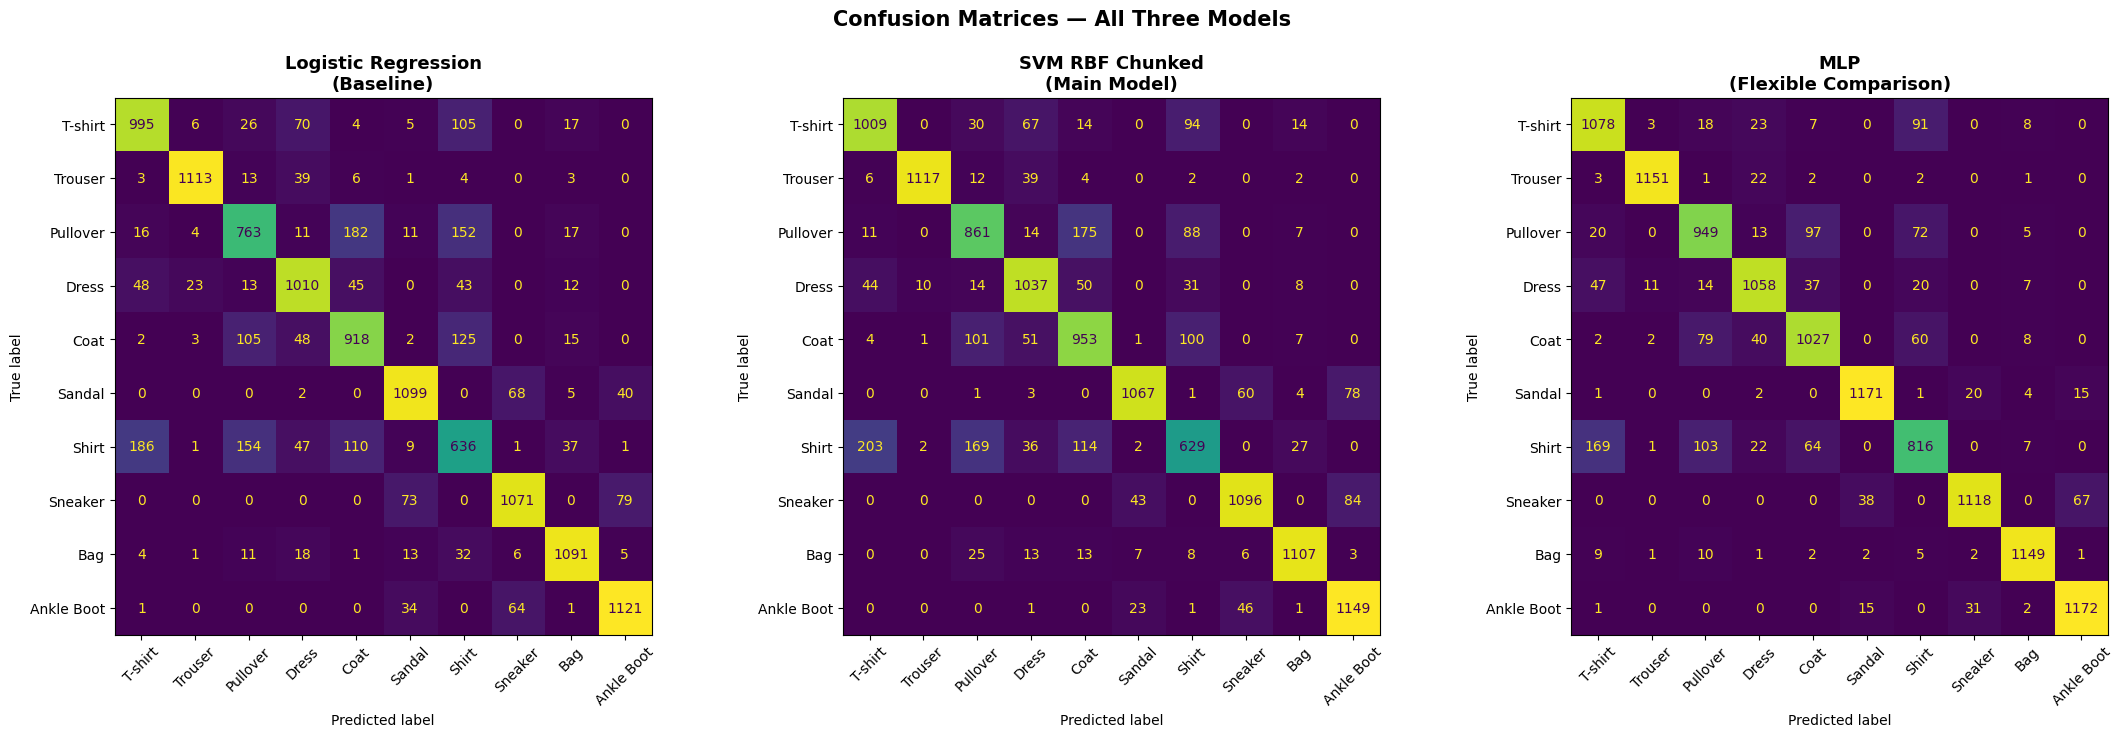

Confusion matrices saved.


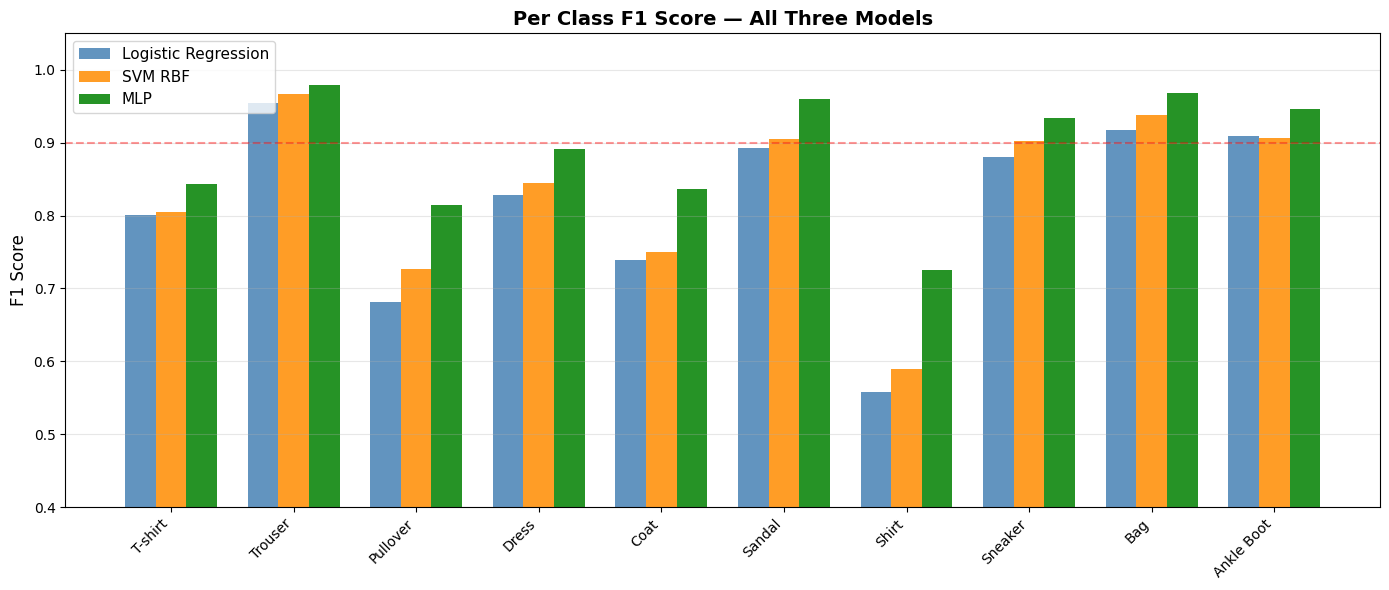

Per class F1 chart saved.


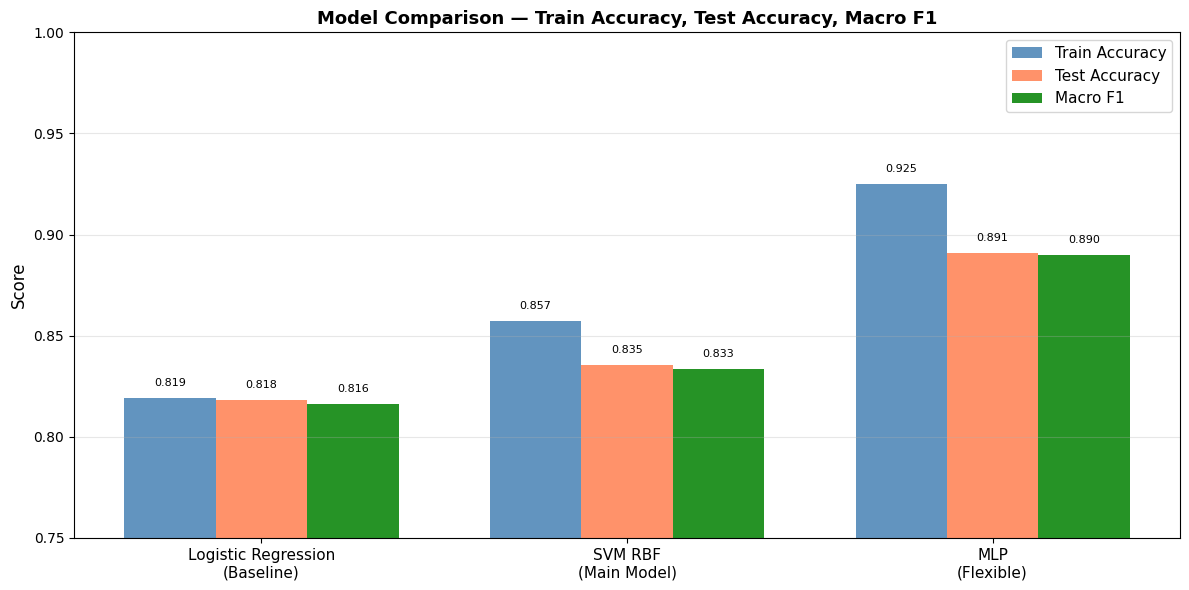

Model comparison chart saved.


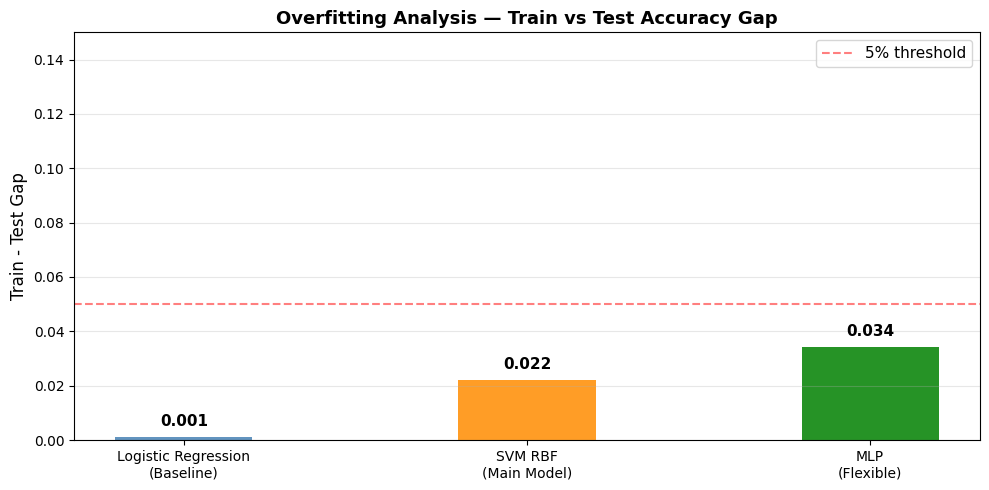

Overfitting analysis chart saved.


In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, classification_report)

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot']

# Get predictions from all three models [Laiba Khan]
y_pred_lr  = lr_model.predict(X_test_lr)
y_pred_svm = svm_chunked.predict(X_test_pca)
y_pred_mlp = mlp_model.predict(X_test_pca)

#F1 Scores [Laiba Khan]
f1_lr  = f1_score(y_test, y_pred_lr,  average='macro')
f1_svm = f1_score(y_test, y_pred_svm, average='macro')
f1_mlp = f1_score(y_test, y_pred_mlp, average='macro')

print(f"Logistic Regression  — Macro F1: {f1_lr:.4f}")
print(f"SVM Chunked          — Macro F1: {f1_svm:.4f}")
print(f"MLP                  — Macro F1: {f1_mlp:.4f}")

# Classification Reports [Ayesha Zulfiqar]
print("\n" + "="*60)
print("LOGISTIC REGRESSION (Baseline)")
print("="*60)
print(classification_report(y_test, y_pred_lr,
                            target_names=class_names))

print("="*60)
print("SVM RBF CHUNKED (Main Model)")
print("="*60)
print(classification_report(y_test, y_pred_svm,
                            target_names=class_names))

print("="*60)
print("MLP (Flexible)")
print("="*60)
print(classification_report(y_test, y_pred_mlp,
                            target_names=class_names))

#Figure 1  Confusion Matrices [Ayesha Zulfiqar]
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

for ax, y_pred, title in zip(
    axes,
    [y_pred_lr, y_pred_svm, y_pred_mlp],
    ['Logistic Regression\n(Baseline)',
     'SVM RBF Chunked\n(Main Model)',
     'MLP\n(Flexible Comparison)']
):
    cm   = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(title, fontsize=13, fontweight='bold')

plt.suptitle('Confusion Matrices — All Three Models',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrices saved.")

#  Figure 2 Per Class F1 Score Comparison [Laiba Khan]
f1_lr_per  = f1_score(y_test, y_pred_lr,  average=None)
f1_svm_per = f1_score(y_test, y_pred_svm, average=None)
f1_mlp_per = f1_score(y_test, y_pred_mlp, average=None)

x     = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))
bars1 = ax.bar(x - width,     f1_lr_per,  width,
               label='Logistic Regression', color='steelblue',  alpha=0.85)
bars2 = ax.bar(x,             f1_svm_per, width,
               label='SVM RBF',             color='darkorange', alpha=0.85)
bars3 = ax.bar(x + width,     f1_mlp_per, width,
               label='MLP',                 color='green',      alpha=0.85)

ax.set_ylabel('F1 Score', fontsize=12)
ax.set_title('Per Class F1 Score — All Three Models',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_ylim(0.4, 1.05)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.9, color='red', linestyle='--',
           alpha=0.4, label='0.9 threshold')

plt.tight_layout()
plt.savefig('f1_per_class.png', dpi=150, bbox_inches='tight')
plt.show()
print("Per class F1 chart saved.")

# Figure 3 Overall Accuracy and F1 Comparison [Ayesha Zulfiqar]
models     = ['Logistic Regression\n(Baseline)',
              'SVM RBF\n(Main Model)',
              'MLP\n(Flexible)']
test_accs  = [0.8181, 0.8354, 0.8908]
train_accs = [0.8193, 0.8574, 0.9250]
macro_f1s  = [f1_lr,  f1_svm, f1_mlp]

x     = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width,  train_accs, width,
               label='Train Accuracy', color='steelblue', alpha=0.85)
bars2 = ax.bar(x,          test_accs,  width,
               label='Test Accuracy',  color='coral',     alpha=0.85)
bars3 = ax.bar(x + width,  macro_f1s,  width,
               label='Macro F1',       color='green',     alpha=0.85)

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison — Train Accuracy, Test Accuracy, Macro F1',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0.75, 1.0)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.005,
                f'{bar.get_height():.3f}',
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Model comparison chart saved.")

# Figure 4 Train vs Test Gap [Laiba Khan]
gaps = [abs(t - v) for t, v in zip(train_accs, test_accs)]

fig, ax = plt.subplots(figsize=(10, 5))
colors  = ['steelblue', 'darkorange', 'green']
bars    = ax.bar(models, gaps, color=colors, alpha=0.85, width=0.4)

ax.set_ylabel('Train - Test Gap', fontsize=12)
ax.set_title('Overfitting Analysis — Train vs Test Accuracy Gap',
             fontsize=13, fontweight='bold')
ax.set_ylim(0, 0.15)
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.05, color='red', linestyle='--',
           alpha=0.5, label='5% threshold')
ax.legend(fontsize=11)

for bar, gap in zip(bars, gaps):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.003,
            f'{gap:.3f}',
            ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('overfitting_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Overfitting analysis chart saved.")